In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Indian Retail Sales & Profitability Analysis

## Python Exploratory Data Analysis

This notebook uses Python to validate the cleaned retail dataset, explore distributions, investigate profitability drivers, and statistically examine the relationship between discounting and business performance.

In [3]:
df = pd.read_excel(r"C:\Data Analytics Projects\Indian Retail Sales & Profitability Analysis Project\Data\Retail_Clean_Data.xlsx")
df.head()

,customer_id,dob,sales,outlet_type,city_type,category_of_goods,region,segment,sales_date,order_id,...,product_name,quantity,discount,profit,order_year,order_quarter,order_month,month_number,year_month,shipping_days
0,CUST000001,1973-11-29,3344.69,Large,Tier 1,Fast Food,East,Consumer,2023-03-11,ORD000001,...,Burgers - 718,3,0.09,448.24,2020,2,April,4,2020-04,5
1,CUST000002,1987-08-30,37094.41,Medium,Tier 2,Fast Food,East,Corporate,2023-09-09,ORD000002,...,Pizzas - 519,5,0.39,3134.34,2021,1,January,1,2021-01,3
2,CUST000003,1980-12-15,35501.08,Large,Village,Electric Appliances,South,Consumer,2022-08-15,ORD000003,...,Fans - 395,6,0.07,8324.21,2020,3,August,8,2020-08,5
3,CUST000004,1989-05-23,8969.33,Medium,Village,Dairy Products,East,Corporate,2021-01-23,ORD000004,...,Milk - 798,4,0.18,1962.66,2021,4,October,10,2021-10,6
4,CUST000005,1957-12-31,35530.44,Small,Village,Seasonal Fruits & Vegetables,West,Consumer,2020-12-24,ORD000005,...,Tomatoes - 442,4,0.27,2843.93,2019,1,January,1,2019-01,3


In [4]:
df.shape

(100000, 27)

## 1. Data Validation

Before performing exploratory analysis, the cleaned dataset is validated for structure, data types, missing values, duplicates, and consistency with the Excel and SQL results.

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 27 columns):
 #   Column             Non-Null Count   Dtype         
---  ------             --------------   -----         
 0   customer_id        100000 non-null  str           
 1   dob                100000 non-null  datetime64[us]
 2   sales              100000 non-null  float64       
 3   outlet_type        100000 non-null  str           
 4   city_type          100000 non-null  str           
 5   category_of_goods  100000 non-null  str           
 6   region             100000 non-null  str           
 7   segment            100000 non-null  str           
 8   sales_date         100000 non-null  datetime64[us]
 9   order_id           100000 non-null  str           
 10  order_date         100000 non-null  datetime64[us]
 11  ship_date          100000 non-null  datetime64[us]
 12  ship_mode          100000 non-null  str           
 13  state              100000 non-null  str           
 14  

In [8]:
df.duplicated().sum()

np.int64(0)

In [12]:
total_sales = df["sales"].sum()
total_profit = df["profit"].sum()
total_quantity = df["quantity"].sum()
transactions = df["order_id"].nunique()
profit_margin = (total_profit / total_sales) * 100
avg_transaction_value = df["sales"].mean()
avg_discount = df["discount"].mean() * 100
avg_shipping_days = df["shipping_days"].mean()

print(f"Total Sales: ₹{total_sales:,.2f}")
print(f"Total Profit: ₹{total_profit:,.2f}")
print(f"Total Quantity: {total_quantity:,}")
print(f"Transactions: {transactions:,}")
print(f"Profit Margin: {profit_margin:.2f}%")
print(f"Average Transaction Value: ₹{avg_transaction_value:,.2f}")
print(f"Average Discount: {avg_discount:.2f}%")
print(f"Average Shipping Days: {avg_shipping_days:.2f}")

Total Sales: ₹2,508,441,014.18
Total Profit: ₹375,530,511.43
Total Quantity: 549,376
Transactions: 100,000
Profit Margin: 14.97%
Average Transaction Value: ₹25,084.41
Average Discount: 25.13%
Average Shipping Days: 3.99


## 2. Exploratory Data Analysis

This section explores the main numerical variables to understand their ranges, averages, distributions, and any unusual patterns before performing business-focused analysis.

In [34]:
numeric_summary = df[
    [
        "sales",
        "profit",
        "quantity",
        "discount",
        "shipping_days"
    ]
].describe()

numeric_summary.round(2)

,sales,profit,quantity,discount,shipping_days
count,100000.00,100000.00,100000.00,100000.00,100000.00
mean,25084.41,3755.31,5.49,0.25,3.99
std,14403.19,2639.85,2.88,0.14,2.01
min,100.57,6.52,1.00,0.00,1.00
25%,12618.03,1651.10,3.00,0.13,2.00
50%,25134.70,3317.45,5.00,0.25,4.00
75%,37575.85,5363.84,8.00,0.38,6.00
max,49999.89,14563.67,10.00,0.50,7.00


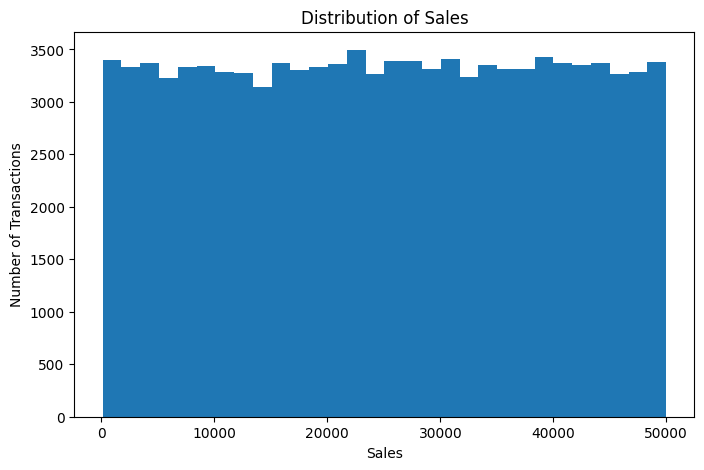

In [35]:
plt.figure(figsize=(8, 5))

plt.hist(df["sales"], bins=30)

plt.title("Distribution of Sales")
plt.xlabel("Sales")
plt.ylabel("Number of Transactions")

plt.show()

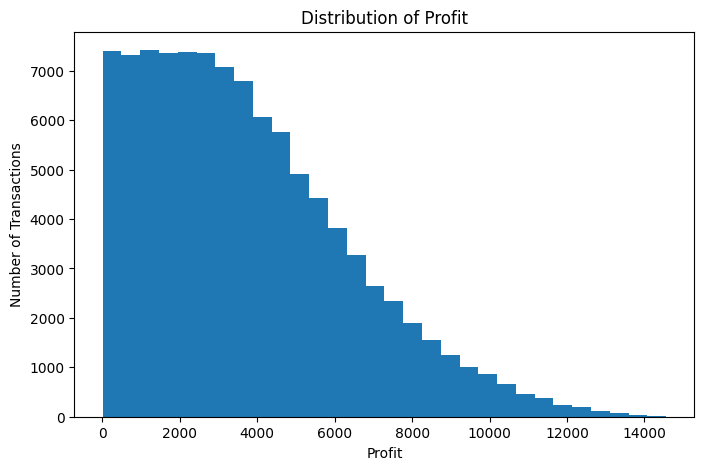

In [36]:
plt.figure(figsize=(8, 5))

plt.hist(df["profit"], bins=30)

plt.title("Distribution of Profit")
plt.xlabel("Profit")
plt.ylabel("Number of Transactions")

plt.show()

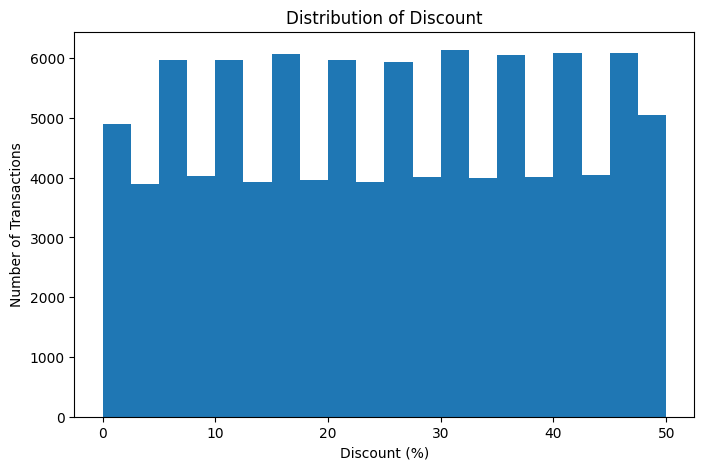

In [37]:
plt.figure(figsize=(8, 5))

plt.hist(df["discount"] * 100, bins=20)

plt.title("Distribution of Discount")
plt.xlabel("Discount (%)")
plt.ylabel("Number of Transactions")

plt.show()

## 3. Discount and Profitability Analysis

The Excel and SQL analysis showed that discounting had the strongest relationship with profitability.  
Python is used here to group transactions into discount bands and compare Sales, Profit, and Profit Margin across those groups.

In [39]:
df["discount_band"] = pd.cut(
    df["discount"],
    bins=[0, 0.10, 0.20, 0.30, 0.40, 0.50],
    labels=[
        "0-10%",
        "10-20%",
        "20-30%",
        "30-40%",
        "40-50%"
    ],
    include_lowest=True
)

In [41]:
discount_analysis = (
    df.groupby("discount_band", observed=False)
      .agg(
          transactions=("order_id", "count"),
          total_sales=("sales", "sum"),
          average_sales=("sales", "mean"),
          total_profit=("profit", "sum"),
          average_profit=("profit", "mean")
      )
)

discount_analysis

,transactions,total_sales,average_sales,total_profit,average_profit
discount_band,,,,,
0-10%,20739,5.184967e+08,25001.046986,98248729.45,4737.389915
10-20%,19924,5.028354e+08,25237.675205,84760583.33,4254.195108
20-30%,19917,4.984635e+08,25027.037871,74162046.49,3723.555078
30-40%,20212,5.076296e+08,25115.259115,65572048.67,3244.213768
40-50%,19208,4.810157e+08,25042.468213,52787103.49,2748.183230


In [43]:
discount_analysis["profit_margin_pct"] = (
    discount_analysis["total_profit"]
    / discount_analysis["total_sales"]
    * 100
)
discount_analysis.round(2)

,transactions,total_sales,average_sales,total_profit,average_profit,profit_margin_pct
discount_band,,,,,,
0-10%,20739,5.184967e+08,25001.05,98248729.45,4737.39,18.95
10-20%,19924,5.028354e+08,25237.68,84760583.33,4254.20,16.86
20-30%,19917,4.984635e+08,25027.04,74162046.49,3723.56,14.88
30-40%,20212,5.076296e+08,25115.26,65572048.67,3244.21,12.92
40-50%,19208,4.810157e+08,25042.47,52787103.49,2748.18,10.97


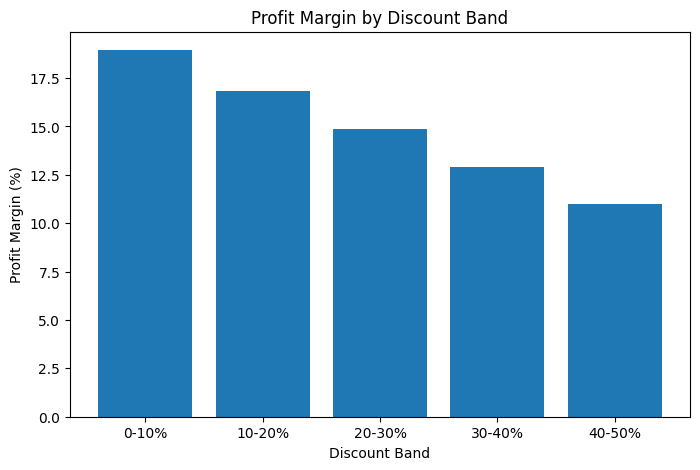

In [44]:
plt.figure(figsize=(8, 5))

plt.bar(
    discount_analysis.index.astype(str),
    discount_analysis["profit_margin_pct"]
)

plt.title("Profit Margin by Discount Band")
plt.xlabel("Discount Band")
plt.ylabel("Profit Margin (%)")

plt.show()

## 4. Discount Impact by Product Category

This section checks whether the decline in profitability at higher discount levels is consistent across different product categories.

In [46]:
category_discount = (
    df.groupby(
        ["category_of_goods", "discount_band"],
        observed=False
    )
    .agg(
        total_sales=("sales", "sum"),
        total_profit=("profit", "sum"),
        transactions=("order_id", "count")
    )
)

category_discount["profit_margin_pct"] = (
    category_discount["total_profit"]
    / category_discount["total_sales"]
    * 100
)

category_discount.round(2)

total_sales  total_profit  \
category_of_goods            discount_band                              
Dairy Products               0-10%          86120326.29   16384551.00   
                             10-20%         84030525.33   14241546.27   
                             20-30%         83239436.34   12268762.22   
                             30-40%         85148066.25   10948699.84   
                             40-50%         79473316.78    8748872.28   
Electric Appliances          0-10%          88038895.37   16718760.42   
                             10-20%         81624031.06   13761751.81   
                             20-30%         82469818.74   12278275.34   
                             30-40%         85284226.88   11031553.20   
                             40-50%         81412636.34    8912652.16   
Fast Food                    0-10%          83870351.20   15911193.95   
                             10-20%         86846541.80   14702080.29   
                             20-30%         82850061.50   12362978.76   
                             30-40%         84411430.24   10993189.47   
                             40-50%         79872451.66    8818394.63   
Furniture                    0-10%          85803583.29   16132837.95   
                             10-20%         82743314.85   13965729.90   
                             20-30%         81047577.56   12122490.39   
                             30-40%         83290661.74   10674120.03   
                             40-50%         81132170.83    8913925.83   
Household Items              0-10%          87438418.66   16624397.08   
                             10-20%         83805608.15   14004896.74   
                             20-30%         83399124.99   12456444.93   
                             30-40%         84821860.57   10939176.70   
                             40-50%         80323883.08    8846378.42   
Seasonal Fruits & Vegetables 0-10%          87225138.64   16476989.05   
                             10-20%         83785419.59   14084578.32   
                             20-30%         85457494.15   12673094.85   
                             30-40%         84673371.55   10985309.43   
                             40-50%         78801270.75    8546880.17   

                                            transactions  profit_margin_pct  
category_of_goods            discount_band                                   
Dairy Products               0-10%                  3448              19.03  
                             10-20%                 3338              16.95  
                             20-30%                 3308              14.74  
                             30-40%                 3364              12.86  
                             40-50%                 3159              11.01  
Electric Appliances          0-10%                  3525              18.99  
                             10-20%                 3233              16.86  
                             20-30%                 3279              14.89  
                             30-40%                 3373              12.94  
                             40-50%                 3236              10.95  
Fast Food                    0-10%                  3366              18.97  
                             10-20%                 3391              16.93  
                             20-30%                 3362              14.92  
                             30-40%                 3368              13.02  
                             40-50%                 3247              11.04  
Furniture                    0-10%                  3419              18.80  
                             10-20%                 3284              16.88  
                             20-30%                 3234              14.96  
                             30-40%                 3303              12.82  
                             40-50%                 3226             

In [47]:
category_margin_table = (
    category_discount["profit_margin_pct"]
    .unstack()
    .round(2)
)

category_margin_table

discount_band,0-10%,10-20%,20-30%,30-40%,40-50%
category_of_goods,,,,,
Dairy Products,19.03,16.95,14.74,12.86,11.01
Electric Appliances,18.99,16.86,14.89,12.94,10.95
Fast Food,18.97,16.93,14.92,13.02,11.04
Furniture,18.80,16.88,14.96,12.82,10.99
Household Items,19.01,16.71,14.94,12.90,11.01
Seasonal Fruits & Vegetables,18.89,16.81,14.83,12.97,10.85


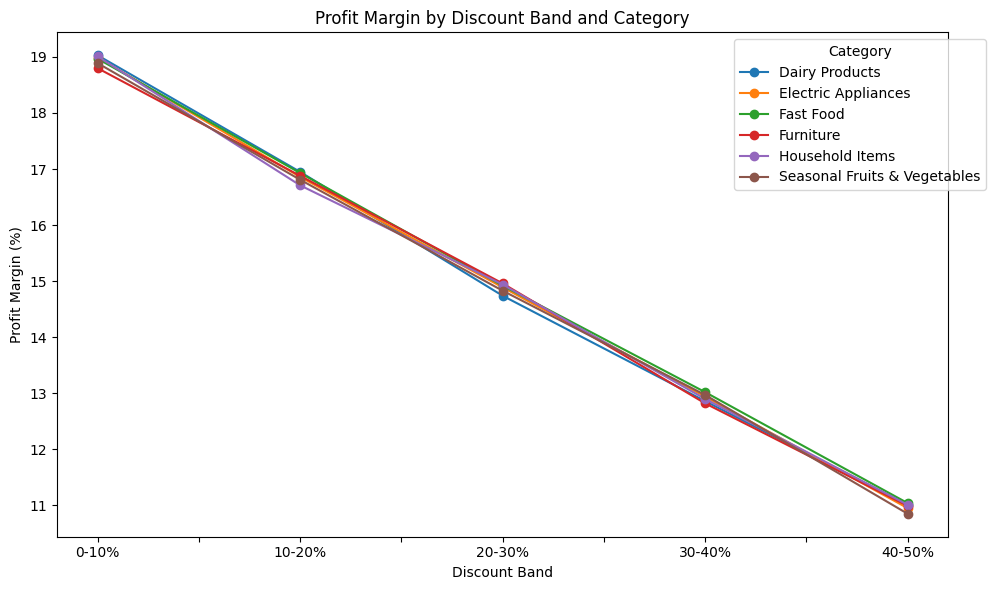

In [48]:
category_margin_table.T.plot(
    figsize=(10, 6),
    marker="o"
)

plt.title("Profit Margin by Discount Band and Category")
plt.xlabel("Discount Band")
plt.ylabel("Profit Margin (%)")
plt.legend(title="Category", bbox_to_anchor=(1.05, 1))
plt.tight_layout()

plt.show()

## 5. Profitability Gap Between Low and High Discounts

This section measures the difference in profitability between the lowest and highest discount bands.

In [49]:
low_discount_margin = discount_analysis.loc[
    "0-10%",
    "profit_margin_pct"
]

high_discount_margin = discount_analysis.loc[
    "40-50%",
    "profit_margin_pct"
]

margin_gap = low_discount_margin - high_discount_margin

print(f"Low Discount Margin: {low_discount_margin:.2f}%")
print(f"High Discount Margin: {high_discount_margin:.2f}%")
print(f"Margin Gap: {margin_gap:.2f} percentage points")

Low Discount Margin: 18.95%
High Discount Margin: 10.97%
Margin Gap: 7.97 percentage points


In [50]:
low_avg_profit = discount_analysis.loc[
    "0-10%",
    "average_profit"
]

high_avg_profit = discount_analysis.loc[
    "40-50%",
    "average_profit"
]

profit_decline_pct = (
    (low_avg_profit - high_avg_profit)
    / low_avg_profit
    * 100
)

print(f"Low Discount Avg Profit: ₹{low_avg_profit:,.2f}")
print(f"High Discount Avg Profit: ₹{high_avg_profit:,.2f}")
print(f"Decline in Avg Profit: {profit_decline_pct:.2f}%")

Low Discount Avg Profit: ₹4,737.39
High Discount Avg Profit: ₹2,748.18
Decline in Avg Profit: 41.99%


In [51]:
category_margin_gap = category_margin_table.copy()

category_margin_gap["margin_gap_pp"] = (
    category_margin_gap["0-10%"]
    - category_margin_gap["40-50%"]
)

category_margin_gap[
    ["0-10%", "40-50%", "margin_gap_pp"]
].sort_values(
    "margin_gap_pp",
    ascending=False
)

discount_band,0-10%,40-50%,margin_gap_pp
category_of_goods,,,
Seasonal Fruits & Vegetables,18.89,10.85,8.04
Electric Appliances,18.99,10.95,8.04
Dairy Products,19.03,11.01,8.02
Household Items,19.01,11.01,8.00
Fast Food,18.97,11.04,7.93
Furniture,18.80,10.99,7.81


## 6. Key Findings

- The cleaned dataset contained 100,000 transactions and 27 columns, with no missing values or duplicate rows.
- Python KPI results matched the results previously obtained in Excel and PostgreSQL.
- Sales values were broadly distributed across the transaction range, while Profit showed greater concentration toward lower values.
- Discount analysis showed that average transaction Sales remained close to ₹25,000 across all discount bands.
- Average Profit per transaction declined from approximately ₹4,756 in the 0–10% discount band to approximately ₹2,784 in the 40–50% band.
- Profit Margin declined from approximately 19.05% to 11.09%, a difference of 7.96 percentage points.
- Average Profit per transaction declined by approximately 41.5% between the lowest and highest discount bands.
- The same profitability pattern appeared across all six product categories, with a margin gap of roughly 8 percentage points.

### Conclusion

Higher discount levels were consistently associated with lower profitability, while average transaction Sales remained relatively stable.

This suggests that discounting is the most important profitability pattern identified in the dataset. However, the analysis shows an association and does not prove that discounts alone caused the reduction in profitability.